# Wildberries vs Amazon: базовое сравнение

Одна и та же задача (оценка 1–5 по тексту отзыва) на двух площадках и языках. Четыре датасета:

| датасет | файл | откуда |
|---|---|---|
| WB full | `data/wb_reviews.csv.gz` | наш парсер (`parser/`) |
| WB balanced | `data/wb_reviews_balanced.csv` | андерсэмплинг WB full до размера самого редкого класса |
| Amazon full | `data/amazon_reviews.csv.gz` | Amazon Reviews 2023 (McAuley Lab), `amazon/prepare.py` |
| Amazon balanced | `data/amazon_reviews_balanced.csv` | андерсэмплинг Amazon full |

Выборка Amazon построена так же, как WB:
- только отзывы с текстом ≥10 символов;
- только товары с ≥3 такими отзывами;
- не больше 100 отзывов на товар;
- ~300k отзывов, поровну из 5 категорий физических товаров (Fashion, Beauty, Handmade, Health, Appliances).

In [1]:
import ast
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 150)
SEED = 0
DATASETS = ['WB', 'Amazon']

In [2]:
# приводим оба датасета к общим колонкам: product_id, rating, full_text, n_words
def load_wb(path):
    """WB reviews without the label-noise rows flagged by WB itself."""
    df = pd.read_csv(path)
    df = df[~df.excluded_from_rating.apply(lambda s: 'sentimentCollision' in ast.literal_eval(s)['reasons'])]
    return df.rename(columns={'imt_id': 'product_id'})


def load_amazon(path):
    """Amazon reviews as built by amazon/prepare.py."""
    return pd.read_csv(path, keep_default_na=False)


data = {
    ('WB', 'full'): load_wb('data/wb_reviews.csv.gz'),
    ('WB', 'balanced'): load_wb('data/wb_reviews_balanced.csv'),
    ('Amazon', 'full'): load_amazon('data/amazon_reviews.csv.gz'),
    ('Amazon', 'balanced'): load_amazon('data/amazon_reviews_balanced.csv'),
}
for df in data.values():
    df['n_words'] = df.full_text.str.split().str.len()

pd.DataFrame({f'{name} {kind}': {'отзывов': len(df), 'товаров': df.product_id.nunique(),
                                 'на класс (min)': df.rating.value_counts().min()}
              for (name, kind), df in data.items()}).T

,отзывов,товаров,на класс (min)
WB full,299722,9172,8491
WB balanced,42340,7136,8381
Amazon full,300034,26352,15522
Amazon balanced,77610,20475,15522


## 1. Данные

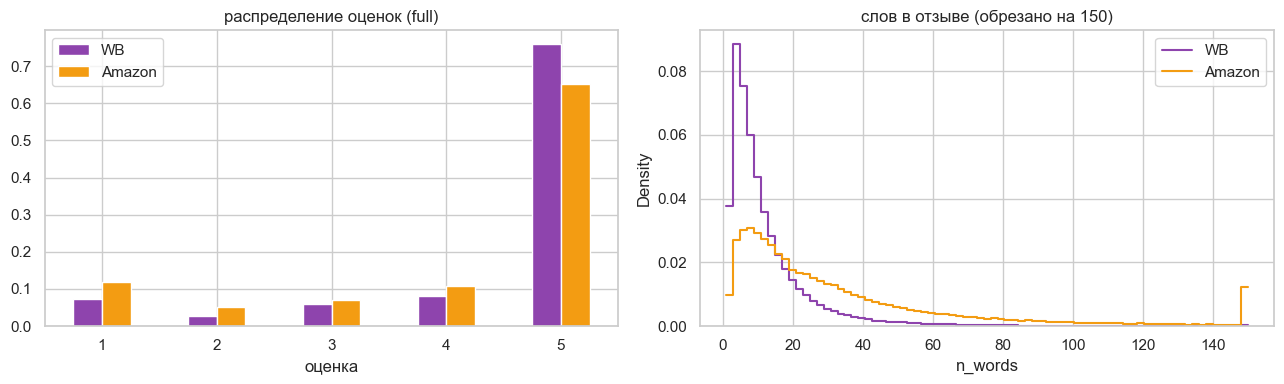

rating,1,2,3,4,5
WB,0.072,0.028,0.059,0.082,0.759
Amazon,0.118,0.052,0.070,0.108,0.652


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dist = pd.DataFrame({name: data[(name, 'full')].rating.value_counts(normalize=True).sort_index() for name in DATASETS})
dist.plot.bar(ax=axes[0], rot=0, color=['#8e44ad', '#f39c12'])
axes[0].set_title('распределение оценок (full)')
axes[0].set_xlabel('оценка')
for name, color in zip(DATASETS, ['#8e44ad', '#f39c12']):
    sns.histplot(data[(name, 'full')].n_words.clip(upper=150), bins=75, stat='density', element='step',
                 fill=False, color=color, label=name, ax=axes[1])
axes[1].set_title('слов в отзыве (обрезано на 150)')
axes[1].legend()
plt.tight_layout()
plt.show()
dist.round(3).T

In [4]:
summary = {}
for name in DATASETS:
    df = data[(name, 'full')]
    per_product = df.groupby('product_id').size()
    summary[name] = {
        'средняя оценка': df.rating.mean(),
        'медиана слов': df.n_words.median(),
        'p95 слов': df.n_words.quantile(0.95),
        'точные дубликаты текста': df.full_text.duplicated().mean(),
        'отзывов на товар (медиана)': per_product.median(),
        'доля дисперсии оценки, объяснённая товаром': df.groupby('product_id').rating.transform('mean').var() / df.rating.var(),
    }
pd.DataFrame(summary).round(3)

,WB,Amazon
средняя оценка,4.427,4.125
медиана слов,8.000,22.000
p95 слов,35.000,107.000
точные дубликаты текста,0.056,0.029
отзывов на товар (медиана),14.000,5.000
"доля дисперсии оценки, объяснённая товаром",0.132,0.257


In [5]:
pd.concat({name: data[(name, 'full')].groupby('rating').n_words.median() for name in DATASETS}, axis=1).T

rating,1,2,3,4,5
WB,10.0,11.0,11.0,11.0,7.0
Amazon,26.0,30.0,29.0,29.0,19.0


In [6]:
# amazon: категории и подставленные заголовки «Five Stars», которые раскрывали бы оценку
amazon = data[('Amazon', 'full')]
print(amazon.groupby('category').rating.agg(['size', 'mean']).round(2))
print(f'\nзаголовков вида «N stars» удалено: {amazon.star_title.sum():,} ({amazon.star_title.mean():.1%})')
print(amazon[amazon.star_title].rating.value_counts().sort_index().to_string())

                           size  mean
category                             
All_Beauty                60007  3.96
Amazon_Fashion            60002  4.02
Appliances                60016  4.18
Handmade_Products         60008  4.51
Health_and_Personal_Care  60001  3.97

заголовков вида «N stars» удалено: 30,694 (10.2%)
rating
1     2552
2     1457
3     2242
4     3688
5    20755


In [7]:
# характерные слова: log-odds негатива (1–2) против 5
def log_odds_words(df, token_re, stop, k=15):
    """Top negative and positive words by log-odds of 1-2 vs 5 ratings."""
    tokens = df.full_text.str.lower().str.findall(token_re).apply(lambda ws: [w for w in ws if w not in stop])
    neg = tokens[df.rating <= 2].explode().value_counts()
    pos = tokens[df.rating == 5].explode().value_counts()
    vocab = neg.add(pos, fill_value=0)
    vocab = vocab[vocab >= 50].index
    neg, pos = neg.reindex(vocab, fill_value=0), pos.reindex(vocab, fill_value=0)
    odds = np.log((neg + 1) / neg.sum()) - np.log((pos + 1) / pos.sum())
    return odds.nlargest(k).index.tolist(), odds.nsmallest(k).index.tolist()


wb_neg, wb_pos = log_odds_words(data[('WB', 'full')], '[а-яё]{3,}', set())
am_neg, am_pos = log_odds_words(amazon, "[a-z']{3,}", ENGLISH_STOP_WORDS)
pd.DataFrame({'WB 1–2': wb_neg, 'Amazon 1–2': am_neg, 'WB 5': wb_pos, 'Amazon 5': am_pos})

,WB 1–2,Amazon 1–2,WB 5,Amazon 5
0,отклонил,deceptive,костюмчик,cutest
1,ужасное,worthless,находка,complements
2,потраченные,inaccurate,стильная,excelente
3,отказал,disappointing,счастлив,lifesaver
4,отвратительное,returnable,лучшая,exceeded
5,отвратительный,unacceptable,отличные,pleasantly
6,хрень,defeats,шикарные,compliments
7,некачественный,poorly,любовь,outstanding
8,отвратительно,misleading,берём,hermoso
9,ужасные,unsatisfied,комфортная,elegant


## 2. Бейзлайны

Для каждой площадки один и тот же протокол:
- **split по товарам** (80/20, `GroupShuffleSplit`), одинаковый для full и balanced версии: balanced-строки попадают в train или test по товару;
- TF-IDF (слова 1–2 граммы, 200k признаков) + логистическая регрессия;
- три способа обучения:
  - на full без весов;
  - на full с `class_weight='balanced'`;
  - на balanced-датасете;
- оценка на двух тестах: full test (реальное распределение) и balanced test (поровну классов).

In [8]:
def tfidf():
    """Word 1-2 gram tf-idf used by all baselines."""
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=200_000, sublinear_tf=True)


def metrics(y_true, y_pred):
    """Accuracy, macro-F1 and MAE."""
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_f1': f1_score(y_true, y_pred, average='macro'),
            'mae': mean_absolute_error(y_true, y_pred)}


def run(name):
    """Trains the three baselines on one platform and evaluates them on both tests."""
    full, balanced = data[(name, 'full')], data[(name, 'balanced')]
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train_idx, _ = next(splitter.split(full, groups=full.product_id))
    train_products = set(full.product_id.iloc[train_idx])
    splits = {kind: (df[df.product_id.isin(train_products)], df[~df.product_id.isin(train_products)])
              for kind, df in [('full', full), ('balanced', balanced)]}

    configs = [('full', None), ('full', 'balanced'), ('balanced', None)]
    rows, preds = [], {}
    for test_kind in ['full', 'balanced']:
        test = splits[test_kind][1]
        rows.append({'dataset': name, 'model': 'константа 5', 'test': test_kind, 'n_train': 0,
                     **metrics(test.rating, np.full(len(test), 5))})
    for train_kind, weight in configs:
        train = splits[train_kind][0]
        vec = tfidf()
        model = LogisticRegression(max_iter=1000, C=2.0, class_weight=weight)
        model.fit(vec.fit_transform(train.full_text), train.rating)
        label = f'train {train_kind}' + (' + class_weight' if weight else '')
        for test_kind in ['full', 'balanced']:
            test = splits[test_kind][1]
            y_pred = model.predict(vec.transform(test.full_text))
            preds[(label, test_kind)] = (test.rating.to_numpy(), y_pred)
            rows.append({'dataset': name, 'model': label, 'test': test_kind, 'n_train': len(train),
                         **metrics(test.rating, y_pred)})
    return pd.DataFrame(rows), preds


outputs = {name: run(name) for name in DATASETS}
results = pd.concat([outputs[name][0] for name in DATASETS], ignore_index=True)
results.pivot_table(index=['dataset', 'model', 'n_train'], columns='test',
                    values=['macro_f1', 'mae', 'accuracy']).round(3)

accuracy        macro_f1         \
test                                      balanced   full balanced   full   
dataset model                     n_train                                   
Amazon  train balanced            61565      0.544  0.668    0.543  0.509   
        train full                239298     0.490  0.774    0.439  0.505   
        train full + class_weight 239298     0.540  0.712    0.528  0.521   
        константа 5               0          0.191  0.643    0.064  0.157   
WB      train balanced            34075      0.475  0.708    0.473  0.432   
        train full                241595     0.429  0.821    0.362  0.443   
        train full + class_weight 241595     0.482  0.764    0.467  0.457   
        константа 5               0          0.200  0.756    0.067  0.172   

                                               mae         
test                                      balanced   full  
dataset model                     n_train                  
Amazon  train balanced            61565      0.567  0.439  
        train full                239298     0.741  0.331  
        train full + class_weight 239298     0.584  0.382  
        константа 5               0          2.023  0.897  
WB      train balanced            34075      0.748  0.455  
        train full                241595     0.971  0.305  
        train full + class_weight 241595     0.762  0.369  
        константа 5               0          2.006  0.580

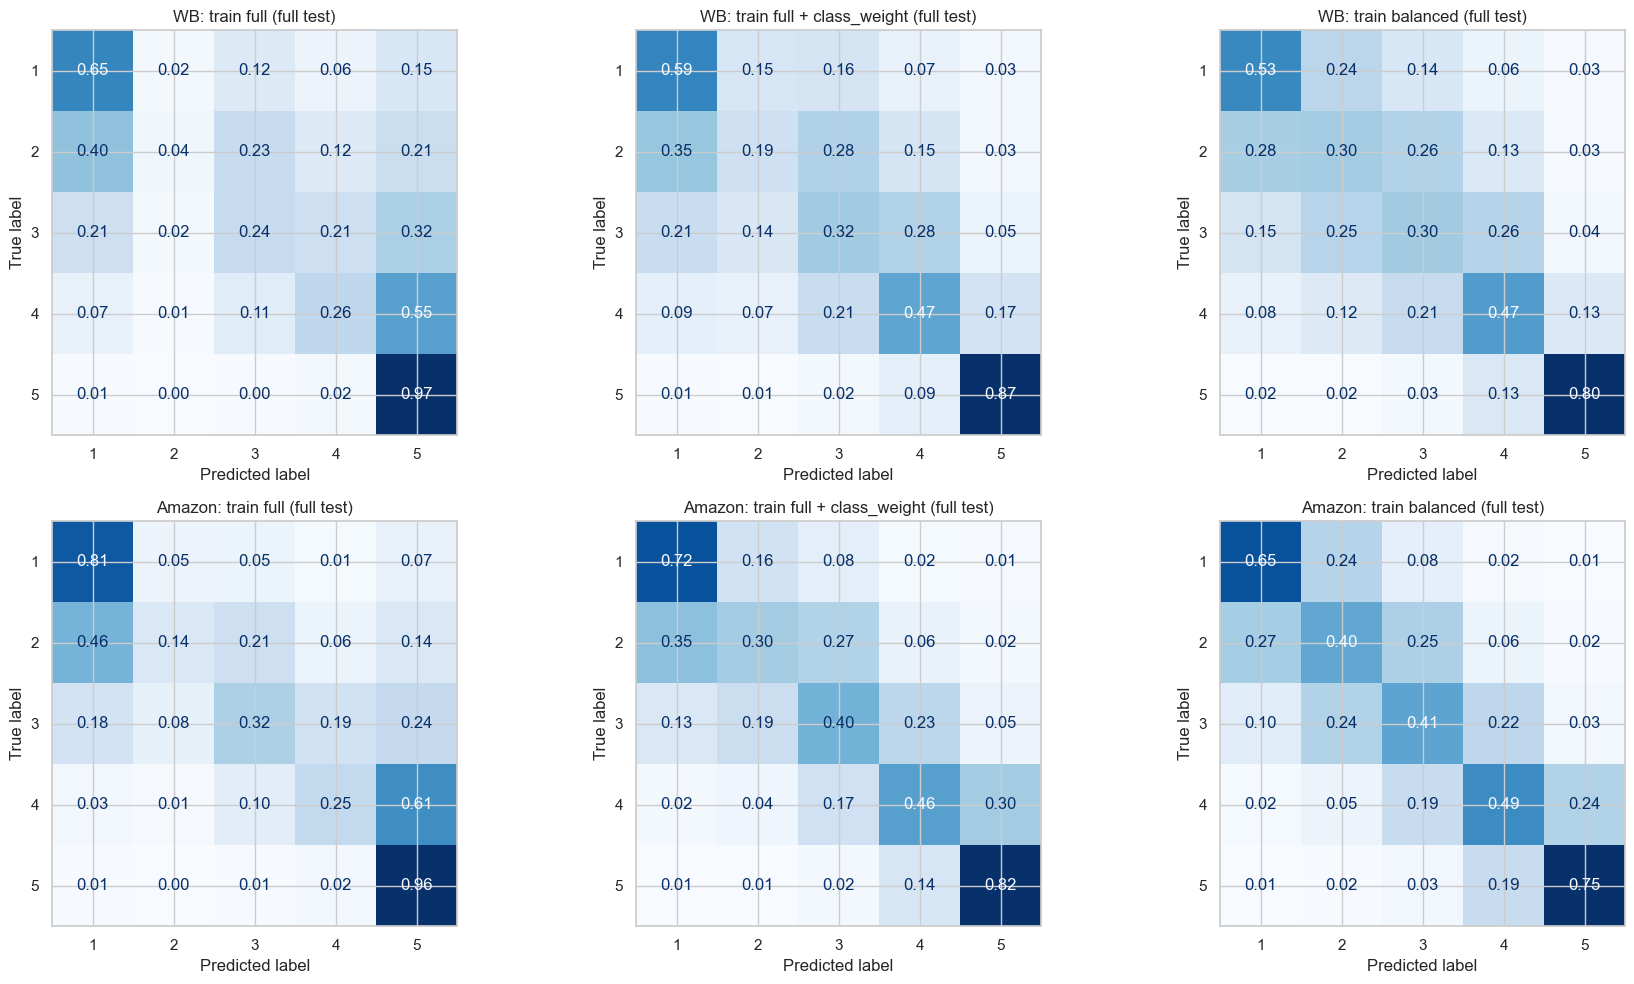

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for row, name in zip(axes, DATASETS):
    for ax, label in zip(row, ['train full', 'train full + class_weight', 'train balanced']):
        y_true, y_pred = outputs[name][1][(label, 'full')]
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, normalize='true', values_format='.2f',
                                                cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(f'{name}: {label} (full test)')
plt.tight_layout()
plt.show()

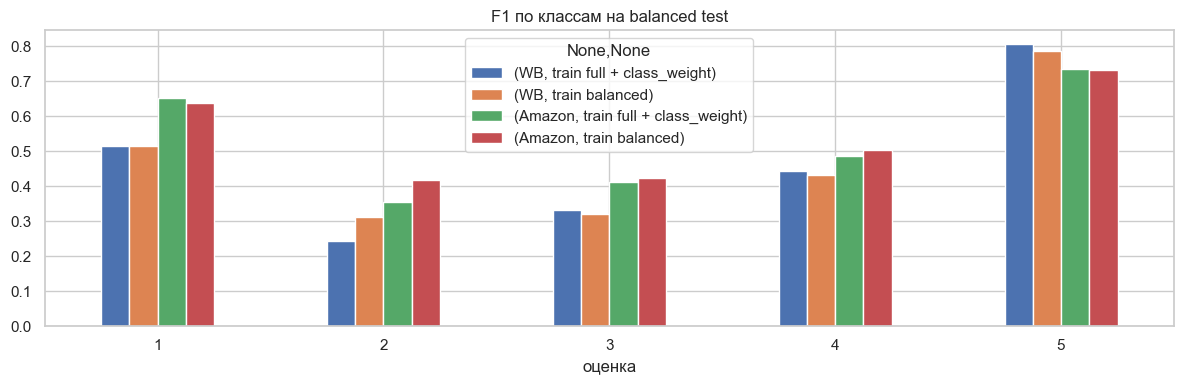

1      2      3      4      5
WB     train full + class_weight  0.514  0.243  0.331  0.443  0.805
       train balanced             0.513  0.313  0.320  0.431  0.787
Amazon train full + class_weight  0.652  0.354  0.413  0.486  0.735
       train balanced             0.638  0.417  0.423  0.504  0.732

In [10]:
# F1 по классам на balanced test
per_class = pd.DataFrame({
    (name, label): f1_score(*outputs[name][1][(label, 'balanced')], average=None)
    for name in DATASETS for label in ['train full + class_weight', 'train balanced']
}, index=[1, 2, 3, 4, 5]).T
ax = per_class.T.plot.bar(figsize=(12, 4), rot=0)
ax.set_title('F1 по классам на balanced test')
ax.set_xlabel('оценка')
plt.tight_layout()
plt.show()
per_class.round(3)

## 3. Выводы

**Данные**
1. **Дисбаланс есть на обеих площадках, но на WB он сильнее:** 5★ 76% против 65% у Amazon, средняя оценка 4.43 против 4.13. На Amazon в 1.6–1.9 раза больше доля оценок 1–2. Balanced-версии: 8.4k на класс у WB и 15.5k на класс у Amazon.
2. **Тексты на Amazon в ~3 раза длиннее** (медиана 22 слова против 8, p95 107 против 35). Паттерн «довольные пишут короче» общий: у 5★ медиана 7 / 19 слов против 10–11 / 26–30 у остальных оценок.
3. **Утечка метки в Amazon:** 10% отзывов имеют автоматический заголовок «Five Stars» / «One Star», который почти точно совпадает с оценкой. Такие заголовки удалены в `amazon/prepare.py`. Без этого метрики на Amazon были бы искусственно завышены.
4. Лексика негатива и позитива похожа по смыслу: «обман» / *scam*, «некачественный» / *poorly*, «разочарование» / *disappointing*. Задача переносится между языками на уровне смысла, но не словаря. Для кросс-язычного переноса нужны мультиязычные эмбеддинги.
5. На Amazon меньше отзывов на товар (медиана 5 против 14), но товар объясняет больше дисперсии оценки (26% против 13%). Отчасти это эффект маленьких групп: среднее по 5 отзывам сильно зависит от каждого из них. Разбиение train/test по товарам обязательно на обеих площадках.

**Бейзлайны** (TF-IDF + LogReg, одинаковый протокол)

6. **Amazon решается лучше:** macro-F1 на balanced test 0.543 против 0.473, MAE 0.57 против 0.75. Вероятные причины: в 3 раза длиннее тексты, больше примеров редких классов (15.5k против 8.4k на класс), меньше шаблонных отзывов.
7. **Ранжирование способов обучения одинаковое на обеих площадках:**
   - balanced-датасет лучший на balanced test (WB 0.473, Amazon 0.543), хотя данных в 4–7 раз меньше;
   - `class_weight` лучший по macro-F1 на реальном распределении (WB 0.457, Amazon 0.521);
   - обучение без весов лучшее по accuracy и MAE на реальном распределении, но почти не предсказывает 2★ (recall 0.04 / 0.14).
8. **Самый трудный класс на обеих площадках 2★** (F1 0.24–0.31 на WB, 0.35–0.42 на Amazon): он смешивается с 1★ и 3★. Ошибки в основном на соседние классы, поэтому имеет смысл ординальная постановка и метрика MAE.

**Что дальше:** сильные модели (fastText, ruBERT / мультиязычный BERT) сравним на этих же четырёх датасетах. Также проверим перенос мультиязычной модели между WB и Amazon (обучение на одном языке, тест на другом).